In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, DBSCAN
from sklearn.datasets import make_blobs, make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

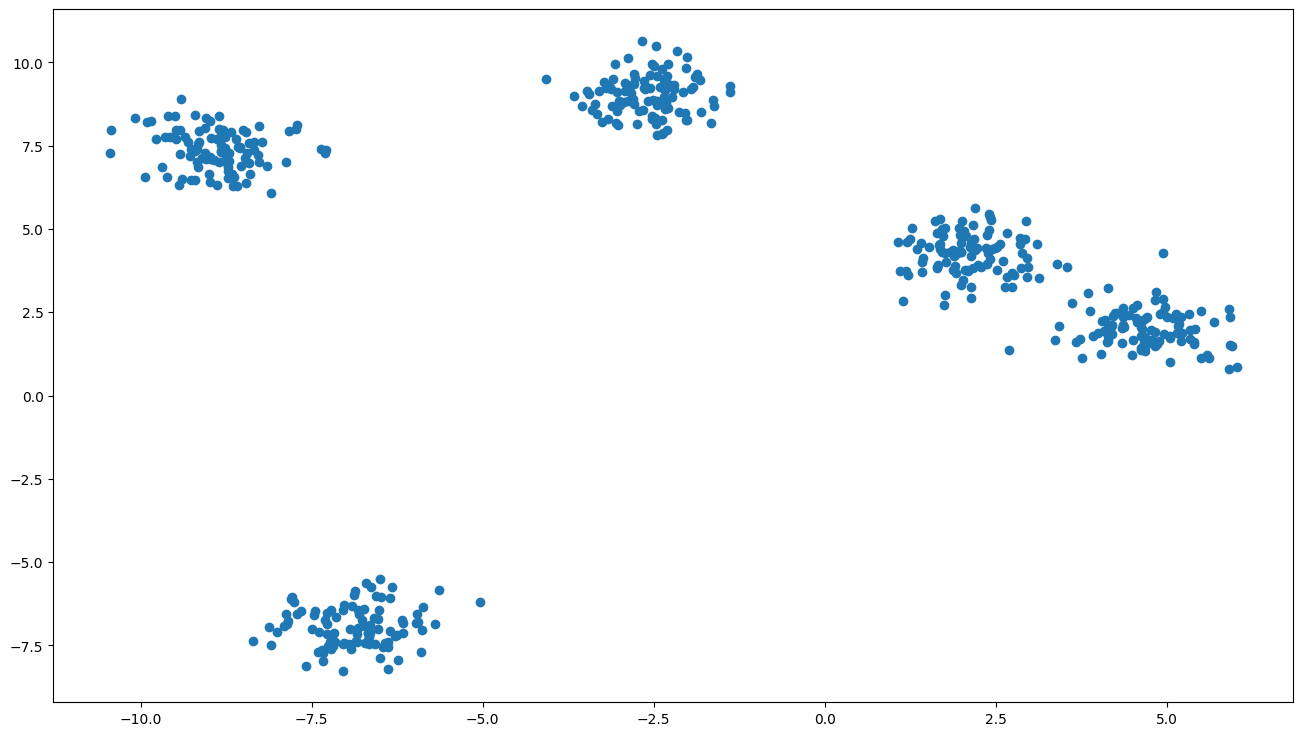

In [3]:
X_sim, y_true = make_blobs(n_samples=500, centers=5, cluster_std=0.60, random_state=42)
plt.figure(figsize=(16, 9))
plt.scatter(X_sim[:, 0], X_sim[:, 1])
plt.show()

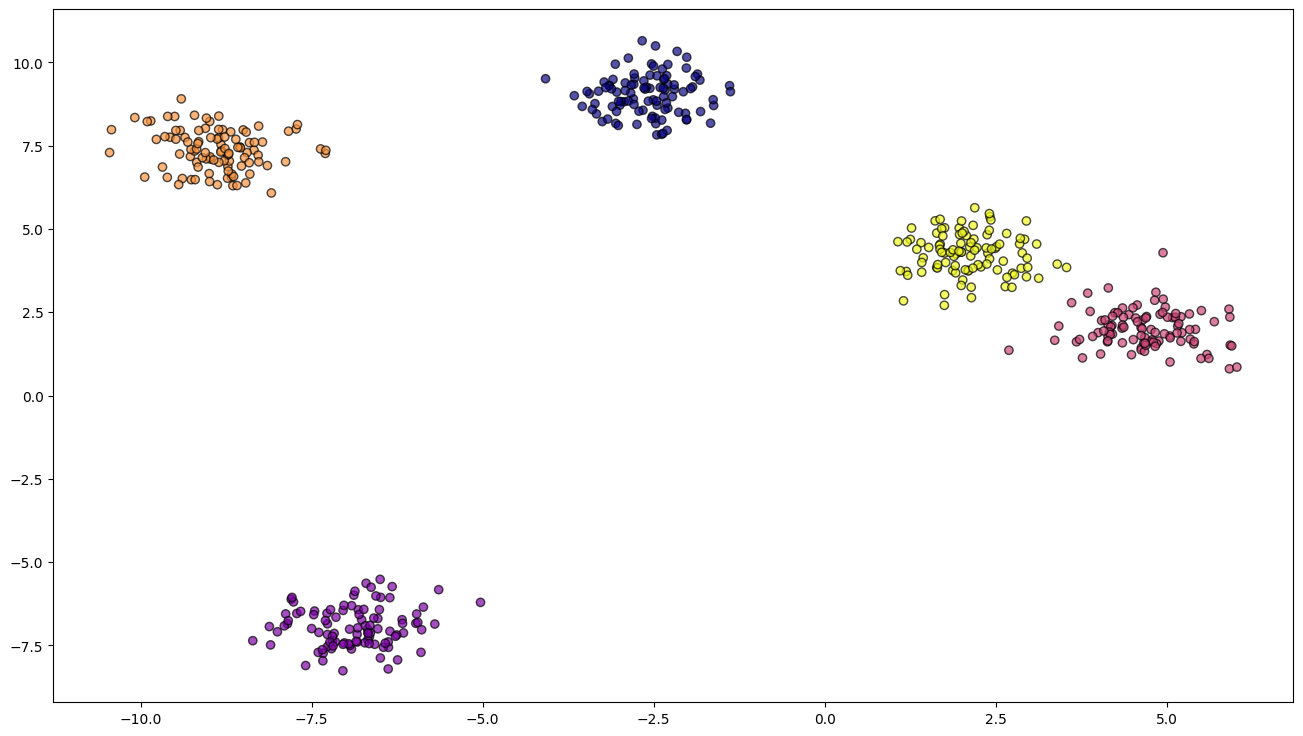

In [6]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_sim)
plt.figure(figsize=(16, 9))
plt.scatter(X_sim[:, 0], X_sim[:, 1], c=labels, cmap='plasma', alpha=0.7, edgecolors='k')

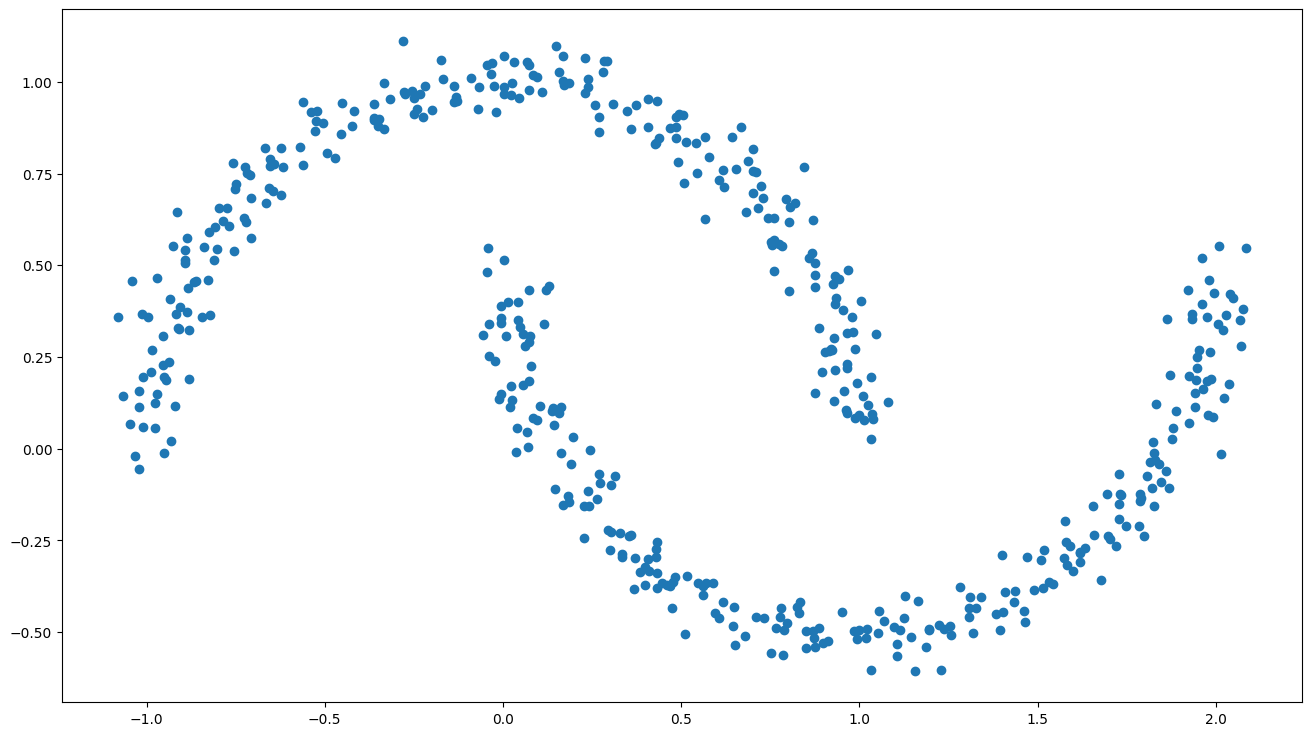

In [54]:
X_moons, y_moons = make_moons(n_samples=500, random_state=42, noise=0.05)
plt.figure(figsize=(16, 9))
plt.scatter(X_moons[:, 0], X_moons[:, 1])
plt.show()

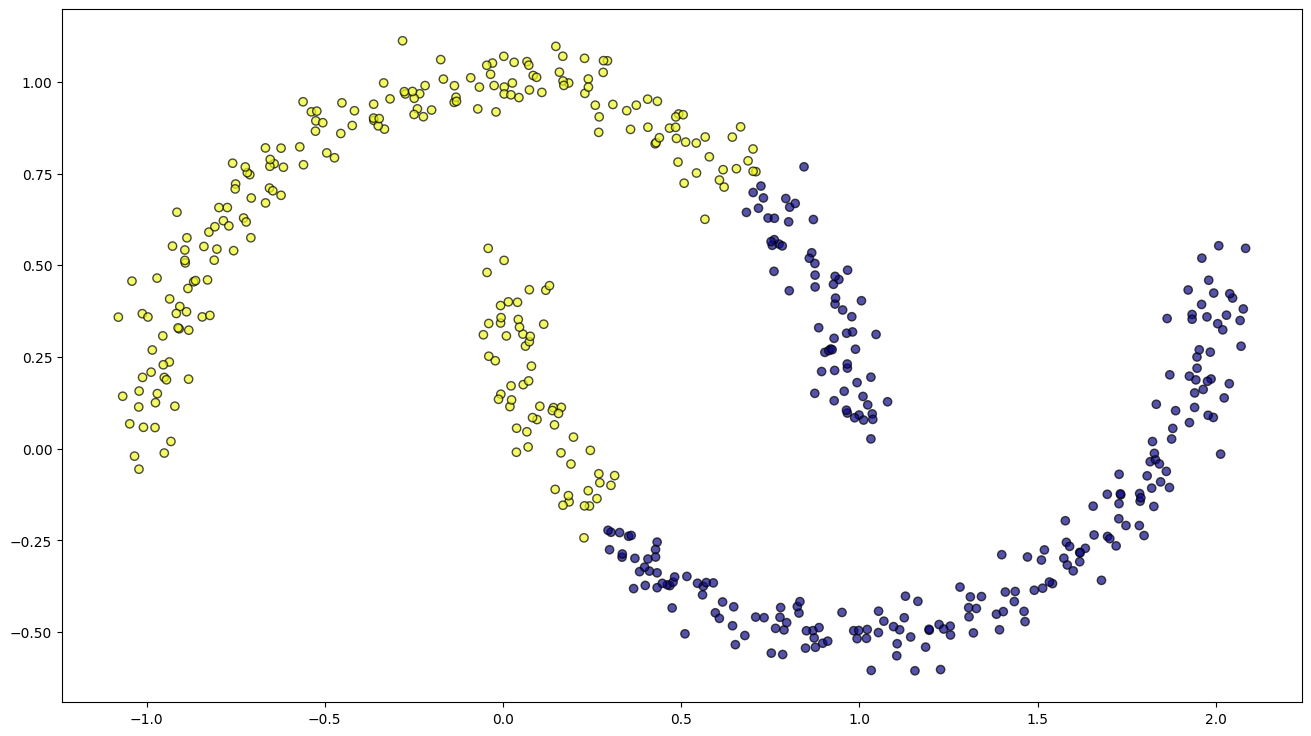

In [55]:
kmeans_moons = KMeans(n_clusters=2, random_state=42, n_init=10)
labels_moons = kmeans_moons.fit_predict(X_moons)
plt.figure(figsize=(16, 9))
plt.scatter(X_moons[:, 0], X_moons[:, 1], c=labels_moons, cmap='plasma', alpha=0.7, edgecolors='k')

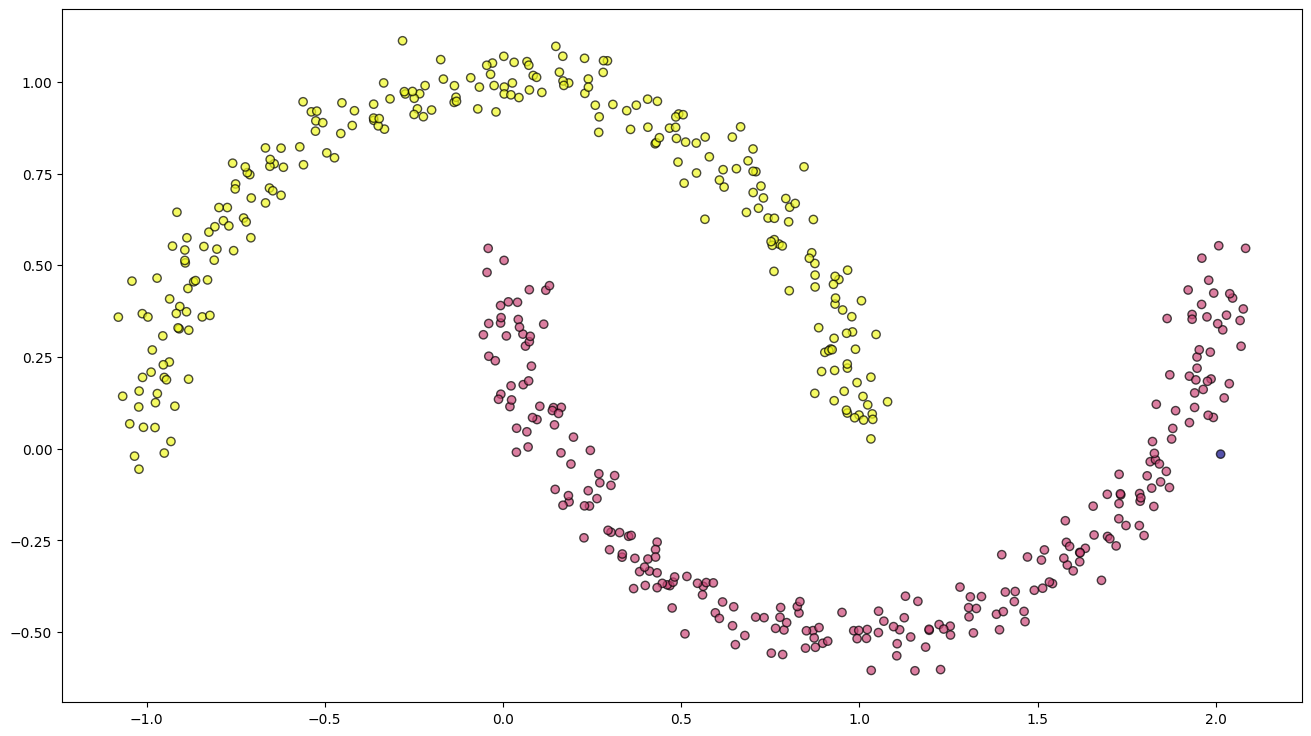

In [75]:
scaler = StandardScaler()
X_moons_scaled = scaler.fit_transform(X_moons)
db_moons = DBSCAN(eps=0.17, min_samples=4)
labels_db = db_moons.fit_predict(X_moons_scaled)
mask = labels_db != -1
plt.figure(figsize=(16, 9))
plt.scatter(X_moons[:, 0], X_moons[:, 1], c=labels_db, cmap='plasma', alpha=0.7, edgecolors='k')

In [74]:
score = silhouette_score(X_moons_scaled[mask], labels_db[mask])
print(score)

0.39651130052507344


In [79]:
from sklearn.decomposition import PCA
from sklearn.datasets import load_wine

wine = load_wine()
X_wine = wine.data
y_wine = wine.target
feature_names = wine.feature_names

scaler_wine = StandardScaler()
X_wine_scaled = scaler.fit_transform(X_wine)

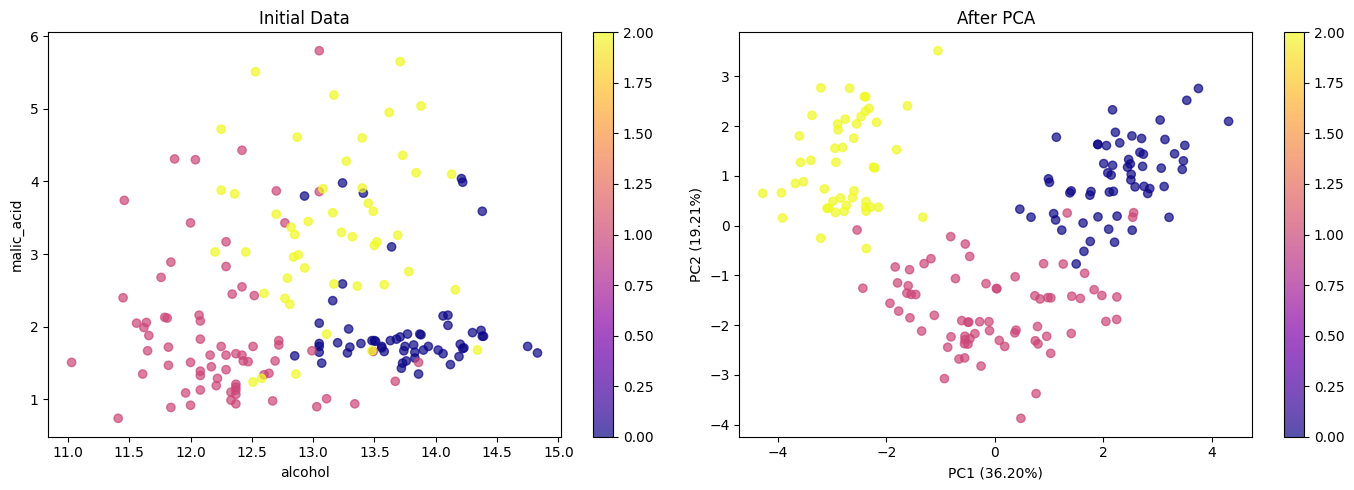

In [81]:
pca_wine = PCA(n_components=2)
X_wine_pca = pca_wine.fit_transform(X_wine_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
scatter1 = axes[0].scatter(X_wine[:, 0], X_wine[:, 1], 
                            c=y_wine, cmap='plasma', alpha=0.7)
axes[0].set_xlabel(feature_names[0])
axes[0].set_ylabel(feature_names[1])
axes[0].set_title('Initial Data')
plt.colorbar(scatter1, ax=axes[0])

scatter2 = axes[1].scatter(X_wine_pca[:, 0], X_wine_pca[:, 1], 
                            c=y_wine, cmap='plasma', alpha=0.7)
axes[1].set_xlabel(f'PC1 ({pca_wine.explained_variance_ratio_[0]:.2%})')
axes[1].set_ylabel(f'PC2 ({pca_wine.explained_variance_ratio_[1]:.2%})')
axes[1].set_title('After PCA')
plt.colorbar(scatter2, ax=axes[1])

plt.tight_layout()
plt.show()

Contribution of features to principal components:
                                PC1    PC2
alcohol                       0.144  0.484
malic_acid                   -0.245  0.225
ash                          -0.002  0.316
alcalinity_of_ash            -0.239 -0.011
magnesium                     0.142  0.300
total_phenols                 0.395  0.065
flavanoids                    0.423 -0.003
nonflavanoid_phenols         -0.299  0.029
proanthocyanins               0.313  0.039
color_intensity              -0.089  0.530
hue                           0.297 -0.279
od280/od315_of_diluted_wines  0.376 -0.164
proline                       0.287  0.365


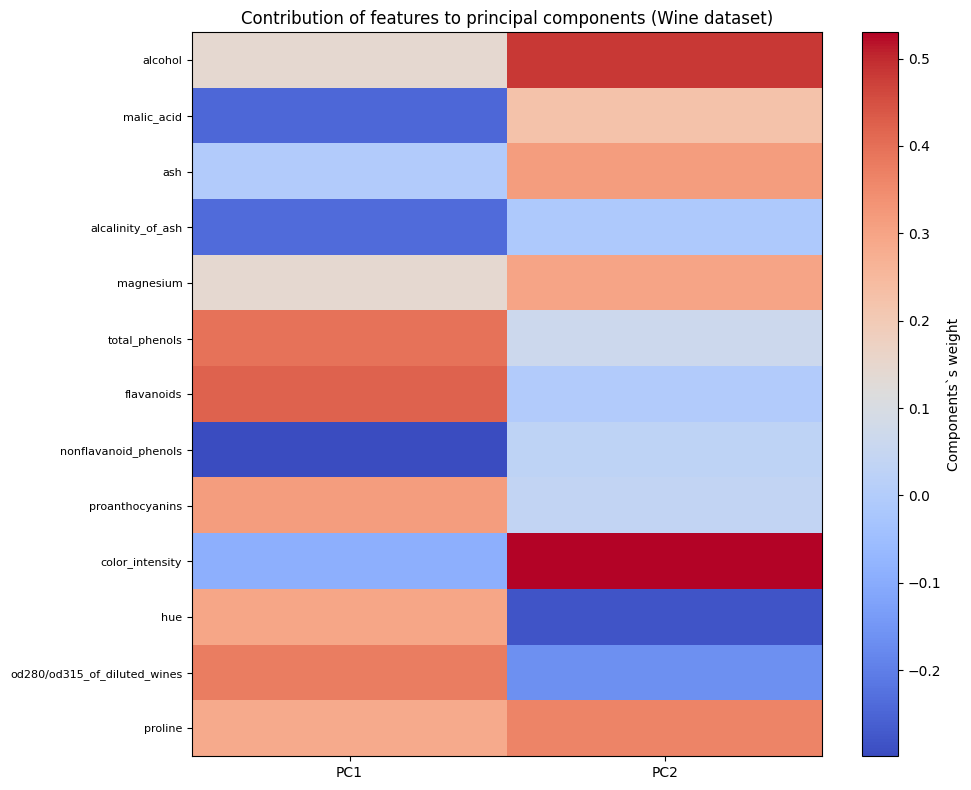

In [85]:
pca_components = pd.DataFrame(
    pca_wine.components_.T,
    columns=['PC1', 'PC2'],
    index=feature_names
)

print("Contribution of features to principal components:")
print(pca_components.round(3))

# Визуализация вклада признаков
plt.figure(figsize=(10, 8))
plt.imshow(pca_wine.components_.T, cmap='coolwarm', aspect='auto')
plt.colorbar(label='Components`s weight')
plt.xticks(range(2), ['PC1', 'PC2'])
plt.yticks(range(len(feature_names)), feature_names, fontsize=8)
plt.title('Contribution of features to principal components (Wine dataset)')
plt.tight_layout()
plt.show()